In [1]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
from scipy.ndimage import maximum_filter, label
import multiprocessing as mp
import os
import fifpy

In [2]:
#Function Definitions
def partial_x_2d(f,dx):
    """Compute ∂f/∂x using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dx = np.zeros_like(f)
    
    # Central difference in x-direction (axis=0)
    df_dx[1:Nx-1, :] = (f[2:Nx, :] - f[0:Nx-2, :]) / (2 * dx)
    
    # Periodic boundaries (x-direction)
    df_dx[0, :] = (f[1, :] - f[-1, :]) / (2 * dx)
    df_dx[-1, :] = (f[0, :] - f[-2, :]) / (2 * dx)
    
    return df_dx

def partial_y_2d(f,dy):
    """Compute ∂f/∂y using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dy = np.zeros_like(f)
    
    # Central difference in y-direction (axis=1)
    df_dy[:, 1:Ny-1] = (f[:, 2:Ny] - f[:, 0:Ny-2]) / (2 * dy)
    
    # Periodic boundaries (y-direction)
    df_dy[:, 0] = (f[:, 1] - f[:, -1]) / (2 * dy)
    df_dy[:, -1] = (f[:, 0] - f[:, -2]) / (2 * dy)
    
    return df_dy

def partial_x_fft(f, dx):
    """
    Calculate ∂f/∂x using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dx (float): Grid spacing in the x-direction.

    Returns:
        df_dx (2D np.array): Partial derivative ∂f/∂x.
    """
    nx, ny = f.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi  # Wavenumbers in x
    kx = kx[:, np.newaxis]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dx_hat = 1j * kx * f_hat
    df_dx = np.fft.ifft2(df_dx_hat).real

    return np.array(df_dx)

def partial_y_fft(f, dy):
    """
    Calculate ∂f/∂y using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dy (float): Grid spacing in the y-direction.

    Returns:
        df_dy (2D np.array): Partial derivative ∂f/∂y.
    """
    nx, ny = f.shape
    ky = np.fft.fftfreq(ny, d=dy) * 2 * np.pi  # Wavenumbers in y
    ky = ky[np.newaxis, :]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dy_hat = 1j * ky * f_hat
    df_dy = np.fft.ifft2(df_dy_hat).real

    return df_dy

def index_of_just_smaller(arr, value):
    arr = np.asarray(arr)
    mask = arr < value
    if not np.any(mask):
        return None  # No smaller value exists
    return np.argmax(np.where(mask, arr, -np.inf))

def iterative_filtering1D(field, index, Xi=1.6):
    fif = fifpy.MIF(NIMFs=4,alpha=30,Xi=Xi)
    fif.run(field)
    print(fif.IMC.shape)
    filtered_signal = np.sum(fif.IMC[index:],axis=0)
    return filtered_signal

In [3]:
# List of simulation directories
base_root = "/home/UNN/w24021992/NAS/simulations_beta_scan"

sim_dirs = [

    # f"{base_root}/beta_p_0.0625/beta_e_0.25",
    # f"{base_root}/beta_p_0.0625/beta_e_1",
    # f"{base_root}/beta_p_0.0625/beta_e_4",

    # f"{base_root}/beta_p_0.25/beta_e_1",
    # f"{base_root}/beta_p_0.25/beta_e_4",
    # f"{base_root}/beta_p_0.25/beta_e_16",

    # f"{base_root}/beta_p_1/beta_e_0.0625",
    # f"{base_root}/beta_p_1/beta_e_0.25",
    # f"{base_root}/beta_p_1/beta_e_1",
    # f"{base_root}/beta_p_1/beta_e_4",
    # f"{base_root}/beta_p_1/beta_e_16",

    # f"{base_root}/beta_p_4/beta_e_0.0625",
    # f"{base_root}/beta_p_4/beta_e_0.25",
    # f"{base_root}/beta_p_4/beta_e_1",
    # # f"{base_root}/beta_p_4/beta_e_4",
    # f"{base_root}/beta_p_4/beta_e_16",
    
    # f"{base_root}/beta_p_16/beta_e_0.0625",
    # f"{base_root}/beta_p_16/beta_e_0.25",
    # f"{base_root}/beta_p_16/beta_e_16",

    f"{base_root}/beta_p_1/beta_e_1"
]

dx = 0.0625
dy = 0.0625

In [4]:
def process_sim_dir(sim_dir):
    J_rms = []
    print(f"{sim_dir}", flush=True)
    for i in range(0, 300):
        print(i)
        File_Bx = f'{sim_dir}/Bx_ApJ_t{i}.h5'
        File_By = f'{sim_dir}/By_ApJ_t{i}.h5'

        with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
            data_Bx = fBx['DS1'][:].T
            data_By = fBy['DS1'][:].T

        data_Bx_filtered = iterative_filtering1D(data_Bx,2)
        data_By_filtered = iterative_filtering1D(data_By,2)

        J_par_FT = partial_x_fft(data_By_filtered, dx) - partial_y_fft(data_Bx_filtered, dy)
        rms = np.sqrt(np.mean(J_par_FT**2))
        J_rms.append(rms)

    return sim_dir, J_rms


if __name__ == "__main__":
    with mp.Pool(processes=32) as pool:   # adjust to number of CPU cores
        results = pool.map(process_sim_dir, sim_dirs)

    all_J_rms = {sim_dir: J_rms for sim_dir, J_rms in results}

/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_1/beta_e_1
0
1
2


KeyboardInterrupt: 

In [4]:
import numpy as np
import h5py
import multiprocessing as mp

TIMES = range(0, 300)


def compute_Jrms(task):
    """One (sim_dir, timestep) -> (sim_dir, t, J_rms)."""
    sim_dir, t = task
    File_Bx = f'{sim_dir}/Bx_ApJ_t{t}.h5'
    File_By = f'{sim_dir}/By_ApJ_t{t}.h5'
    try:
        with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
            data_Bx = fBx['DS1'][:].T
            data_By = fBy['DS1'][:].T
    except OSError:                                     # missing/unreadable snapshot
        return sim_dir, t, np.nan

    data_Bx_filtered = iterative_filtering1D(data_Bx, 2)
    data_By_filtered = iterative_filtering1D(data_By, 2)
    J_par_FT = partial_x_fft(data_By_filtered, dx) - partial_y_fft(data_Bx_filtered, dy)
    rms = np.sqrt(np.mean(J_par_FT**2))
    return sim_dir, t, rms


if __name__ == "__main__":
    # every (directory, timestep) pair is one task -> parallelism is over timesteps
    tasks = [(sd, t) for sd in sim_dirs for t in TIMES]
    t_index = {t: k for k, t in enumerate(TIMES)}       # timestep -> slot in the time-ordered array

    # pre-fill so results can be placed by (sim_dir, t) regardless of completion order
    all_J_rms = {sd: np.full(len(TIMES), np.nan) for sd in sim_dirs}

    with mp.Pool(processes=128) as pool:                 # adjust to number of CPU cores
        done, total = 0, len(tasks)
        for sim_dir, t, rms in pool.imap_unordered(compute_Jrms, tasks, chunksize=1):
            all_J_rms[sim_dir][t_index[t]] = rms
            done += 1
            if done % 50 == 0 or done == total:
                print(f"{done}/{total} done", flush=True)

    # all_J_rms[sim_dir] is now a time-ordered array of J_rms (NaN where a snapshot was missing)

IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMFIMF  11

IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMFIMF IMF1 
1 
1
IMFIMF  11

IMF IMF1
 1
IMF 1IMF
 1
IMF 1
IMF 1IMF
 IMF1
 1
IMFIMF  11

IMF 1
IMFIMF  11

IMF 1
IMF IMF1IMFIMF
   111


IMF 1
IMF 1IMF
 1
IMF 1
IMF 1
IMFIMF IMF 1
1 
1
IMF IMF1IMF 1

 1
IMF 1
IMF IMFIMF1IMF 
 1 1
1

IMF 1
IMF 1IMF
 1
IMFIMF  11

IMF 1
IMFIMF  11

IMF 1
IMF 1
IMFIMF  1
1
IMF 1IMF
 1
IMF IMF1
 1IMF
 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF IMFIMFIMF1   1
11


IMF 1
IMF 1
IMF 1IMFIMF
  11

IMFIMF  11

IMF 1
IMFIMF  11

IMF 1IMF
 1
IMF 1IMF
IMF  11IMF

 1
IMFIMF 1IMF 
1
 IMF1 
1IMF
 1
IMF IMFIMF1
  11IMF

 1
IMF IMF1 
1IMF
 1
IMFIMF  11

IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMFIMF  11

IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 2
IMF 2
IMF 2
IMF 2IMF
 2
IMF IMF 2
2
IMF 2
IMF 2
IMF 2
IMF 2IMF IMF 2IMF
2 2

IMF
 2IMF
 2
IMF 2
IMF 2
IMF 2
IMFIMF 2IMF  2
2
IMF 
2
IMF 2
IMF 2
IMFIMF  22

IMFIMFIMF  22 IMF 
2
2
IMF
 IMF 2
2
IMFIMF IMF 22

IMF  22

IMF IMF 2


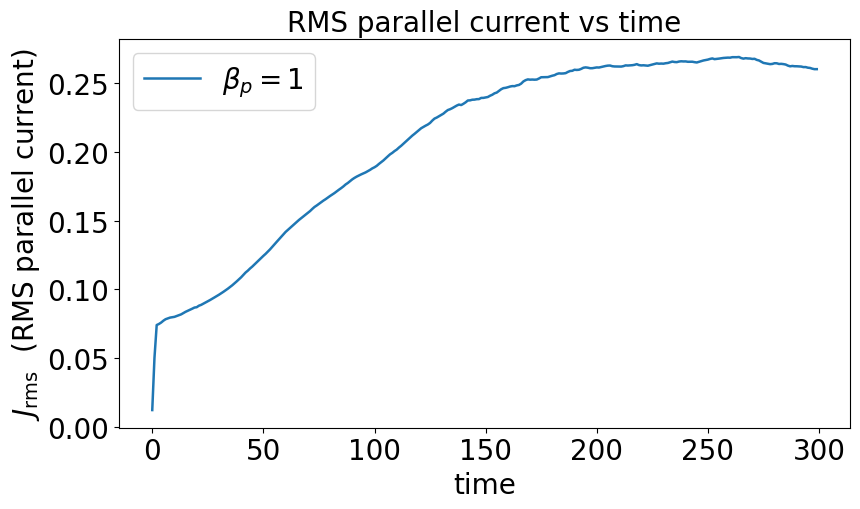

In [8]:
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'figure.titlesize': 20
})

import numpy as np
import matplotlib.pyplot as plt

times = np.array(list(TIMES))

def _beta_of(sim_dir):                       # pull beta_p out of the path for the legend
    for part in sim_dir.rstrip("/").split("/"):
        if part.startswith("beta_p_"):
            try:
                return float(part[len("beta_p_"):])
            except ValueError:
                return None
    return None

ordered = sorted(sim_dirs, key=lambda sd: (_beta_of(sd) is None, _beta_of(sd) or 0.0))

plt.figure(figsize=(9, 5.5))
for sim_dir in ordered:
    y = np.asarray(all_J_rms[sim_dir], float)
    valid = np.isfinite(y)                    # skip missing snapshots (NaN) -> line spans the gap
    beta = _beta_of(sim_dir)
    label = rf"$\beta_p = {beta:g}$" if beta is not None else sim_dir
    plt.plot(times[valid], y[valid], "-", lw=1.8, label=label)

plt.xlabel("time")
plt.ylabel(r"$J_{\mathrm{rms}}$  (RMS parallel current)")
plt.title("RMS parallel current vs time")
plt.legend()
plt.tight_layout()
plt.savefig("Jrms_vs_time.png", dpi=300)
plt.show()

In [6]:
timesteps = np.arange(0, 300)

for sim_dir, J_rms in all_J_rms.items():

    J_rms = np.asarray(J_rms)

    # --- Find global peak ---
    imax = np.argmax(J_rms)
    t_peak = timesteps[imax]
    J_peak = J_rms[imax]

    # --- Create plots directory ---
    plots_dir = os.path.join(sim_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    # --- Plot ---
    plt.figure(figsize=(10, 6))
    plt.plot(timesteps, J_rms, lw=2, label=r'$J_{\mathrm{rms}}$')

    # Vertical line at peak
    plt.axvline(t_peak, linestyle='--', linewidth=1.5)

    # Peak marker
    plt.scatter(t_peak, J_peak, zorder=5)

    # Annotation
    plt.text(
        t_peak,
        J_peak,
        f'  Peak\n  t = {t_peak}\n  $J_{{rms}}$ = {J_peak:.3e}',
        verticalalignment='bottom',
        horizontalalignment='left',
        bbox=dict(boxstyle="round", alpha=0.25)
    )

    plt.xlabel('Timestep')
    plt.ylabel(r'$J_{\mathrm{rms}}$')
    plt.title(rf'$J_{{\mathrm{{rms}}}}$ vs Time')
    # plt.grid(True)
    plt.tight_layout()

    # --- Save ---
    save_path = os.path.join(plots_dir, "Jrms.png")
    plt.savefig(save_path, dpi=300)
    plt.close()

    print(f"Saved Jrms plot with peak annotation: {save_path}")

Saved Jrms plot with peak annotation: /home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_1/beta_e_1/plots/Jrms.png
